# Étape 3 — Analyse non supervisée

L'objectif de cette étape sera d'effectuer une analyse non supervisée (clustering) afin d'appliquer des labels (faibles) sur les images actuellement non labelisées.

Ces nouveaux labels pourront ensuite être utilisés lors du réentrainement du modèle, en étape 4, afin de vérifier s'ils permettent d'améliorer la performance finale (vs une simple utilisation des labels "forts")

## 1. Charger les données

In [1]:
import numpy as np
import pandas as pd

inventaire = pd.read_csv("../data/inventaire.csv")
embeddings = np.load("../data/embeddings.npy")
print(inventaire.shape, embeddings.shape)
assert len(inventaire) == len(embeddings), "L'inventaire et les embeddings ne sont pas alignés !"

# Trois masques : True pour les lignes qui appartiennent au groupe
masque_train = (inventaire["split"] == "train").to_numpy()
masque_test = (inventaire["split"] == "test").to_numpy()
masque_sans = (inventaire["source"] == "sans_label").to_numpy()

emb_train = embeddings[masque_train]
emb_test = embeddings[masque_test]
emb_sans = embeddings[masque_sans]

# Labels en nombres : 1 = cancer, 0 = normal
y_train = (inventaire.loc[masque_train, "label"] == "cancer").astype(int).to_numpy()
y_test = (inventaire.loc[masque_test, "label"] == "cancer").astype(int).to_numpy()

print("Formes :", emb_train.shape, emb_test.shape, emb_sans.shape)
print("Cancers en train / en test :", y_train.sum(), "/", y_test.sum())

(1410, 4) (1410, 2048)
Formes : (69, 2048) (30, 2048) (1311, 2048)
Cancers en train / en test : 35 / 15


On dispose de 69 images labellisées pour l'entraînement (35 cancers, 34 normaux), de 30 images de test (15 / 15), mises de côté et non utilisées dans cette étape, et de 1 311 images sans label. Les labels sont codés 1 = cancer (la classe que l'on cherche à détecter) et 0 = normal.


## 2. Standardisation

In [2]:
from sklearn.preprocessing import StandardScaler

# Les images qu'on a le droit d'utiliser : train labellisé PUIS sans label (l'ordre compte !)
X_clu = np.vstack([emb_train, emb_sans])
inv_clu = pd.concat([inventaire[masque_train], inventaire[masque_sans]], ignore_index=True)
n_train = len(emb_train)       # les n_train premières lignes de X_clu sont les images labellisées

scaler = StandardScaler()
X_clu_std = scaler.fit_transform(X_clu)    # fit SANS le test, puis transform
X_test_std = scaler.transform(emb_test)    # le test est seulement transformé, jamais "fitté"

print("Formes :", X_clu_std.shape, X_test_std.shape)
print("5 premières moyennes      :", X_clu_std.mean(axis=0)[:5].round(3))
print("5 premiers écarts-types   :", X_clu_std.std(axis=0)[:5].round(3))


Formes : (1380, 2048) (30, 2048)
5 premières moyennes      : [0. 0. 0. 0. 0.]
5 premiers écarts-types   : [1. 1. 1. 1. 1.]


La standardisation ramène chaque feature à une moyenne de 0 et un écart-type de 1, pour qu'aucune ne domine les calculs de distance de l'ACP et du clustering. Elle est ajustée (`fit`) sur le train et les images sans label uniquement : le test ne doit influencer aucun choix, même indirectement. Il est seulement transformé avec les moyennes et écarts-types appris ailleurs.

L'ordre d'empilement compte : les 69 premières lignes de `X_clu` sont les images labellisées, les 1 311 suivantes les images sans label. `inv_clu` garde le même ordre, pour retrouver chaque image.

## 3. Visualisation en 2D (ACP)

On dessine d'abord les points gris (images non labelisés), puis les points colorés (images labelisés) par-dessus, pour qu'ils restent visibles.

Variance expliquée par axe : [0.077 0.04 ] | total : 11.7 %


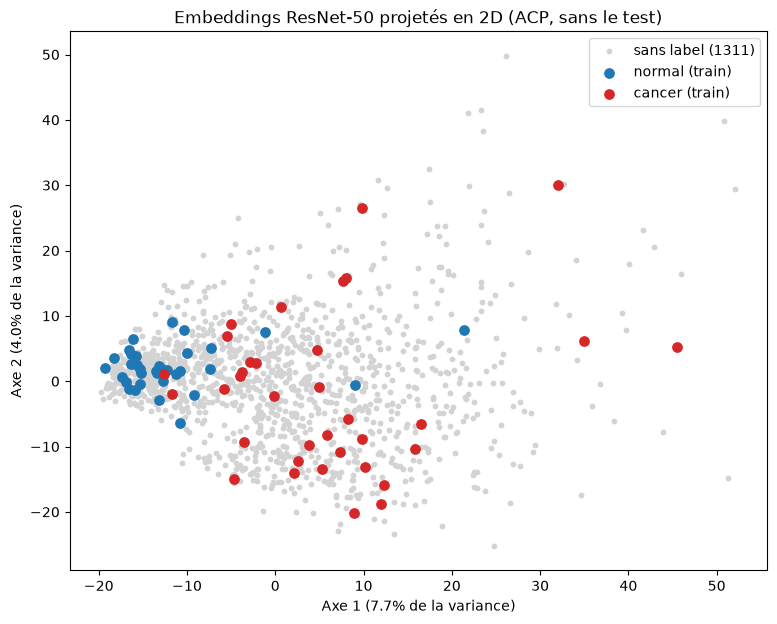

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

acp_2d = PCA(n_components=2, random_state=42)
X_2d = acp_2d.fit_transform(X_clu_std)

var = acp_2d.explained_variance_ratio_
print("Variance expliquée par axe :", var.round(3), "| total :", round(var.sum() * 100, 1), "%")

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(X_2d[n_train:, 0], X_2d[n_train:, 1], c="lightgray", s=10, label="sans label (1311)")
ax.scatter(X_2d[:n_train][y_train == 0, 0], X_2d[:n_train][y_train == 0, 1], c="tab:blue", s=45, label="normal (train)")
ax.scatter(X_2d[:n_train][y_train == 1, 0], X_2d[:n_train][y_train == 1, 1], c="tab:red", s=45, label="cancer (train)")
ax.set_xlabel(f"Axe 1 ({var[0]:.1%} de la variance)")
ax.set_ylabel(f"Axe 2 ({var[1]:.1%} de la variance)")
ax.set_title("Embeddings ResNet-50 projetés en 2D (ACP, sans le test)")
ax.legend()
plt.show()


Les deux premiers axes ne conservent que 11,7 % de la variance : ce graphique est une « ombre » très partielle des données. On y voit pourtant que les cancers et les normaux du train se séparent assez bien le long de l'axe 1.

Afin d'interpréter l'axe 1, regardons les 10 images les plus à gauche, et les 10 images les plus à droite.

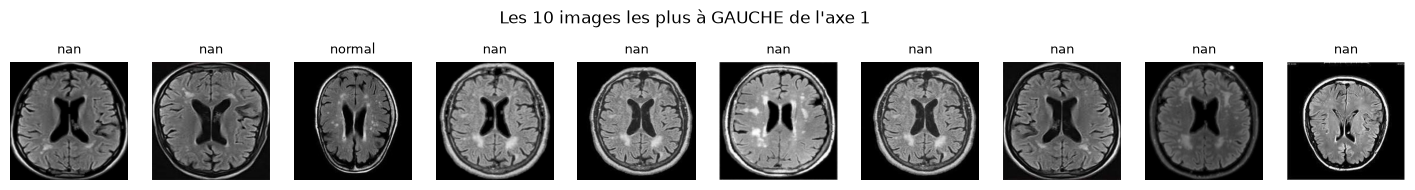

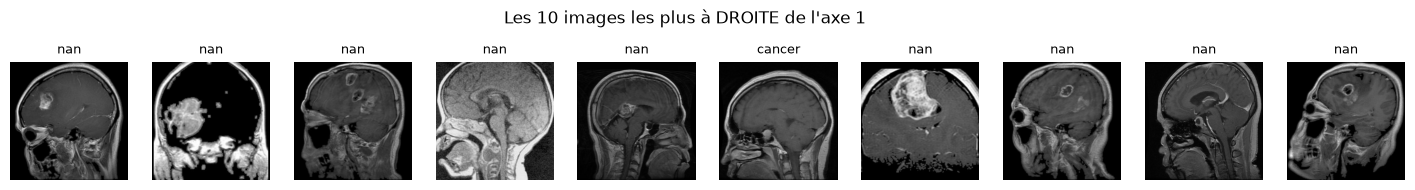

In [4]:
from PIL import Image

ordre = np.argsort(X_2d[:, 0])   # positions des images, de la plus à gauche à la plus à droite sur l'axe 1
for titre, indices in [("Les 10 images les plus à GAUCHE de l'axe 1", ordre[:10]),
                       ("Les 10 images les plus à DROITE de l'axe 1", ordre[-10:])]:
    fig, axes = plt.subplots(1, 10, figsize=(18, 2.3))
    for ax, i in zip(axes, indices):
        ax.imshow(Image.open(inv_clu.loc[i, "chemin"]))
        ax.set_title(str(inv_clu.loc[i, "label"]), fontsize=9)   # cancer, normal, ou nan (sans label)
        ax.axis("off")
    fig.suptitle(titre)
    plt.show()


On remarque que l'axe 1 discrimine selon le plan de coupe, axial sur les images les plus à gauche, autres plans de l'autre. C'est le biais qui avait été noté à l'étape 1.

K-Means travaillera sur beaucoup plus que 2 axes, mais l'axe 1 est celui de plus grande variance, donc il est fort possible qu'il influence significativement la manière dont il coupera l'espace. Risque ; s'il coupe selon le plan de coupe, on aura alors un cluster "non axial" nommé "cancer" et un cluster "axial" nommé "normal", potentiellement des faux négatifs, l'erreur la plus grave.

Néanmoins, on calcule ici une baseline. On vérifiera ce biais après ; contrôle visuel des clusters, comparaison des métriques sur les coupes axiales seules vs sur l'ensemble des images.

## 4. ACP pour le clustering

Composantes gardées pour 90 % de la variance : 495
Formes : (1380, 495) (30, 495)
50% de la variance → 64 composantes
80% de la variance → 297 composantes
90% de la variance → 495 composantes
95% de la variance → 678 composantes


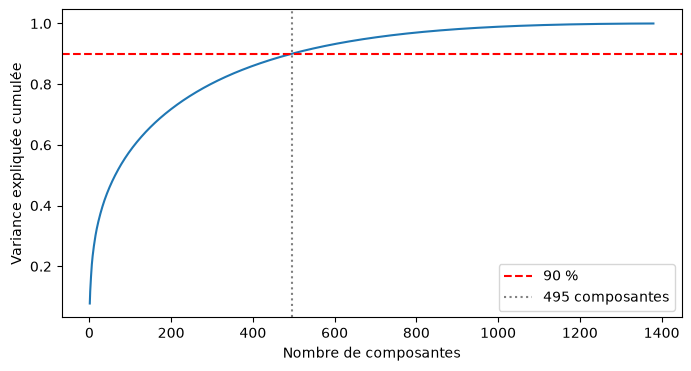

In [5]:
acp = PCA(n_components=0.90, random_state=42)
Z_clu = acp.fit_transform(X_clu_std)          # fit sur train + sans label
Z_test = acp.transform(X_test_std)            # le test est seulement transformé

print("Composantes gardées pour 90 % de la variance :", acp.n_components_)
print("Formes :", Z_clu.shape, Z_test.shape)

# Courbe de variance cumulée, pour voir le compromis
variance_cumulee = np.cumsum(PCA(random_state=42).fit(X_clu_std).explained_variance_ratio_)
for seuil in [0.5, 0.8, 0.9, 0.95]:
    print(f"{seuil:.0%} de la variance → {np.argmax(variance_cumulee >= seuil) + 1} composantes")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(variance_cumulee) + 1), variance_cumulee)
plt.axhline(0.90, color="red", linestyle="--", label="90 %")
plt.axvline(acp.n_components_, color="gray", linestyle=":", label=f"{acp.n_components_} composantes")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.legend()
plt.show()


La courbe s'aplatit : 64 composantes suffisent pour 50 % de la variance, mais il en faut 495 pour 90 % et 678 pour 95 %. L'ACP classe les axes par variance, pas par capacité à séparer les classes (elle ne connaît pas les labels). Garder trop de composantes ajoute surtout du bruit et rend les distances moins parlantes (fléau de la dimension) ; en garder trop peu donnerait encore plus de poids aux premiers axes, dont celui de l'orientation. On teste donc plusieurs valeurs (20, 50, 100 composantes et 90 % de la variance) dans la partie 6.

## 5. K-means et ARI

Appliquons maintenant l'algorithme K-means et calculons son ARI

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
clusters = kmeans.fit_predict(Z_clu)      # un numéro de cluster (0 ou 1) pour chacune des 1380 images

clu_train = clusters[:n_train]            # les clusters des 69 images labellisées
clu_sans = clusters[n_train:]             # les clusters des 1311 images sans label

print("Taille des clusters :", np.bincount(clusters))
print(f"ARI sur le train : {adjusted_rand_score(y_train, clu_train):.3f}")

# Tableau croisé : comment les vrais labels se répartissent dans chaque cluster
print(pd.crosstab(y_train, clu_train, rownames=["vrai label (1 = cancer)"], colnames=["cluster"]))

# Les clusters suivent-ils l'axe 1 de l'ACP (l'axe de l'orientation) ?
print("Position moyenne sur l'axe 1, par cluster :", pd.Series(X_2d[:, 0]).groupby(clusters).mean().round(1).to_dict())


Taille des clusters : [747 633]
ARI sur le train : 0.310
cluster                   0   1
vrai label (1 = cancer)        
0                        32   2
1                        13  22
Position moyenne sur l'axe 1, par cluster : {0: -9.399999618530273, 1: 11.0}


On note un ARI de 0,31 ce qui est plutôt encourageant, nettement mieux que le hasard.
- la précision est très bonne (22 cancers contre 2 normaux pour le cluster "cancer") : 92%
- le rappel est moins bon (13 cancers dans le cluster "normal" vs 22 pour le cluster "cancer") : 63%

On observe également que l'axe 1 est très différenciant pour nos 2 clusters, position moyenne de -9 pour le cluster "normal" vs 11 pour le cluster "cancer", on peut formuler l'hypothèse que les cancers mal placés sont des coupes axiales, et rangés du côté des images normales.

Regardons cette hypothèse

### 5.1 Images de cancer dans cluster "normal"

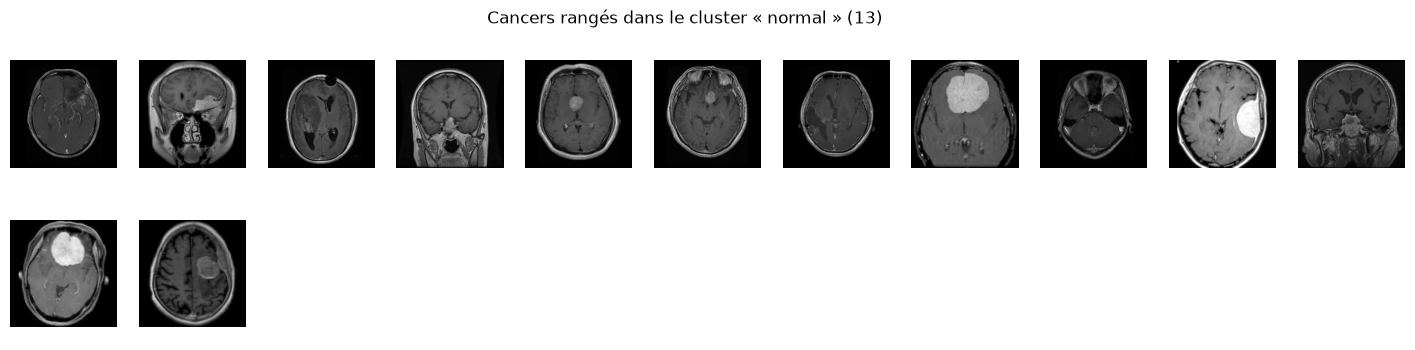

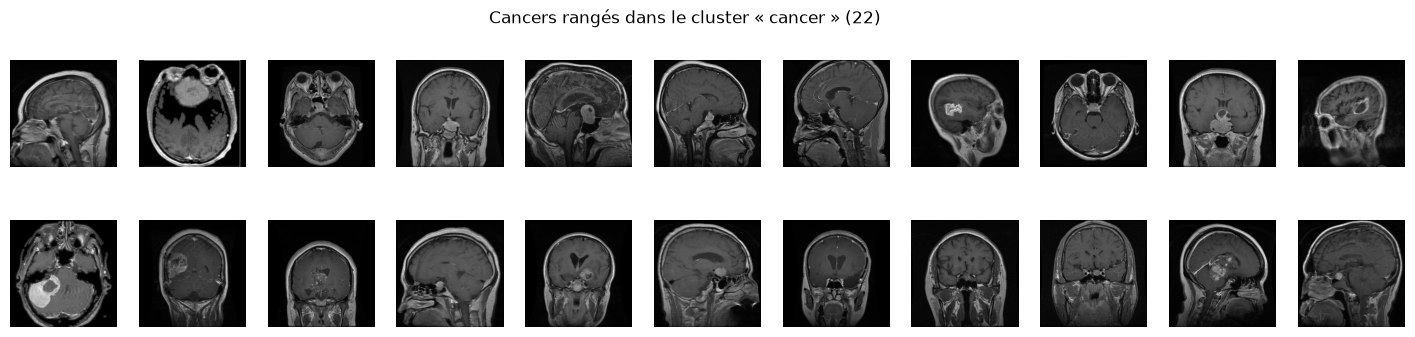

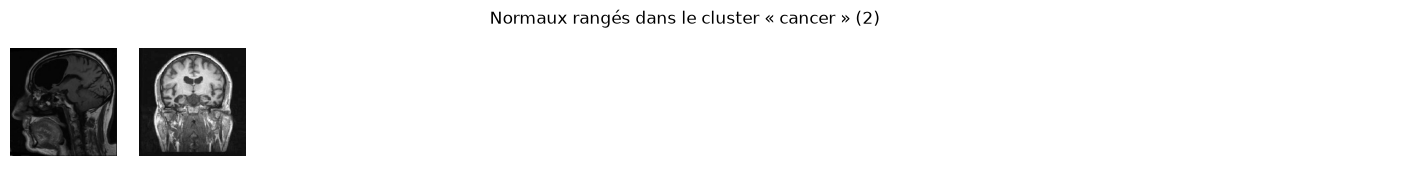

In [7]:
from PIL import Image

def afficher(indices, titre, n_col=11):
    """Affiche les images de inv_clu aux positions données."""
    n_lignes = max(1, int(np.ceil(len(indices) / n_col)))
    fig, axes = plt.subplots(n_lignes, n_col, figsize=(18, 1.9 * n_lignes))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, i in zip(np.ravel(axes), indices):
        ax.imshow(Image.open(inv_clu.loc[i, "chemin"]))
    fig.suptitle(titre)
    plt.show()

# Les positions sont celles du train (0 à 68), qui sont aussi les premières lignes de inv_clu
cancers_mal = np.where((y_train == 1) & (clu_train == 0))[0]
cancers_bien = np.where((y_train == 1) & (clu_train == 1))[0]
normaux_mal = np.where((y_train == 0) & (clu_train == 1))[0]

afficher(cancers_mal, f"Cancers rangés dans le cluster « normal » ({len(cancers_mal)})")
afficher(cancers_bien, f"Cancers rangés dans le cluster « cancer » ({len(cancers_bien)})")
afficher(normaux_mal, f"Normaux rangés dans le cluster « cancer » ({len(normaux_mal)})")


K-means sépare les images selon un mélange de plan de coupe et de pathologie, impossible à démêler ici car les deux sont liés dans les données. Les cancers mal placés sont surtout des coupes axiales (10 sur 13, contre 6 sur 22 pour les cancers bien placés). Conséquence : le cluster « cancer » est fiable (22 cancers pour 2 normaux), mais le cluster « normal » contient de nombreuses tumeurs vues du dessus, qui recevront un label faible erroné.

## 6. Comparaison des méthodes et sensibilité

In [8]:
from sklearn.cluster import AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

def eps_dbscan(Z, k=5):
    """Ordre de grandeur pour eps : la distance médiane de chaque point à son k-ième voisin."""
    distances, _ = NearestNeighbors(n_neighbors=k + 1).fit(Z).kneighbors(Z)
    return np.median(distances[:, k])   # colonne k : le k-ième voisin (la colonne 0, c'est le point lui-même)

resultats = []
for n_comp in [20, 50, 100, 0.90]:
    Z = PCA(n_components=n_comp, random_state=42).fit_transform(X_clu_std)
    methodes = {
        "K-means": KMeans(n_clusters=2, n_init=10, random_state=42),
        "Agglomératif (Ward)": AgglomerativeClustering(n_clusters=2),
        "Mélange gaussien": GaussianMixture(n_components=2, covariance_type="diag", random_state=42),
        "DBSCAN": DBSCAN(eps=eps_dbscan(Z), min_samples=5),
        "HDBSCAN": HDBSCAN(min_cluster_size=25),
    }
    for nom, modele in methodes.items():
        groupes = modele.fit_predict(Z)
        resultats.append({
            "composantes": Z.shape[1],
            "méthode": nom,
            "ARI (train)": round(adjusted_rand_score(y_train, groupes[:n_train]), 3),
            "groupes trouvés": sorted(set(groupes.tolist())),
            "points de bruit": int((groupes == -1).sum()),
        })

tableau = pd.DataFrame(resultats)
display(tableau)
tableau.pivot(index="méthode", columns="composantes", values="ARI (train)")


/Users/matthieu/dev/openclassrooms/projet7/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/matthieu/dev/openclassrooms/projet7/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/matthieu/dev/openclassrooms/projet7/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
/Users/matthieu/dev/openclassrooms/projet7/.venv/lib/python3.12/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True 

,composantes,méthode,ARI (train),groupes trouvés,points de bruit
0,20,K-means,0.310,"[0, 1]",0
1,20,Agglomératif (Ward),0.456,"[0, 1]",0
2,20,Mélange gaussien,-0.004,"[0, 1]",0
3,20,DBSCAN,0.082,"[-1, 0, 1]",507
4,20,HDBSCAN,0.294,"[-1, 0, 1]",1059
5,50,K-means,0.310,"[0, 1]",0
6,50,Agglomératif (Ward),0.497,"[0, 1]",0
7,50,Mélange gaussien,-0.007,"[0, 1]",0
8,50,DBSCAN,0.099,"[-1, 0, 1]",505
9,50,HDBSCAN,0.328,"[-1, 0, 1]",1115


composantes,20,50,100,495
méthode,,,,
Agglomératif (Ward),0.456,0.497,0.584,0.310
DBSCAN,0.082,0.099,0.064,0.119
HDBSCAN,0.294,0.328,0.000,0.000
K-means,0.310,0.310,0.310,0.310
Mélange gaussien,-0.004,-0.007,0.005,0.098


- **K-means** donne exactement le même résultat quel que soit le nombre de composantes (ARI 0,31) : ses distances sont dominées par les premiers axes de l'ACP, les composantes suivantes changent peu la coupure.
- **Agglomératif (Ward)** obtient le meilleur ARI, 0,58 avec 100 composantes, mais il dépend du réglage (0,31 avec 495 composantes) : il fusionne les images de proche en proche et réagit à la structure locale.
- **Mélange gaussien** : ARI proche de 0, il ne retrouve pas les classes.
- **DBSCAN et HDBSCAN** sont inadaptés pour fabriquer des labels faibles. Ces méthodes par densité ne regroupent que les points entourés de nombreux voisins proches et classent les autres en « bruit » (−1) : HDBSCAN laisse 77 % des images sans groupe avec 20 composantes, 81 % avec 50, et toutes avec 100. Nos images ne forment pas deux îles séparées par une zone vide, mais un grand nuage diffus avec quelques noyaux denses. De plus, on ne peut pas leur imposer 2 groupes.
- Les images que HDBSCAN parvient à regrouper sont les cas les plus typiques. C'est une logique proche du « seuil de confiance » de la pseudo-labellisation : moins de labels, mais plus sûrs.

L'ARI n'est calculé que sur 69 images : quelle est sa précision ? Le **bootstrap** recalcule l'ARI sur 1 000 tirages avec remise de ces 69 images ; l'intervalle contenant 90 % des valeurs mesure l'incertitude.

In [9]:
rng = np.random.default_rng(42)

def ari_bootstrap(groupes_train, n_tirages=1000):
    """ARI recalculé sur des tirages avec remise des images du train : renvoie l'intervalle à 90 %."""
    scores = []
    for _ in range(n_tirages):
        i = rng.integers(0, n_train, n_train)           # 69 positions tirées au hasard, avec remise
        scores.append(adjusted_rand_score(y_train[i], groupes_train[i]))
    return np.quantile(scores, [0.05, 0.95]).round(2)

for n_comp in [20, 100]:
    Z = PCA(n_components=n_comp, random_state=42).fit_transform(X_clu_std)
    for nom, modele in [("K-means", KMeans(n_clusters=2, n_init=10, random_state=42)),
                        ("Agglomératif (Ward)", AgglomerativeClustering(n_clusters=2))]:
        g = modele.fit_predict(Z)[:n_train]
        print(f"{n_comp:>3} composantes · {nom:20s} ARI = {adjusted_rand_score(y_train, g):.2f}"
              f" · intervalle à 90 % : {ari_bootstrap(g)}")
        print(pd.crosstab(y_train, g, rownames=["vrai"], colnames=["cluster"]), "\n")

 20 composantes · K-means              ARI = 0.31 · intervalle à 90 % : [0.14 0.5 ]
cluster   0   1
vrai           
0        32   2
1        13  22 

 20 composantes · Agglomératif (Ward)  ARI = 0.46 · intervalle à 90 % : [0.28 0.68]
cluster   0   1
vrai           
0         2  32
1        26   9 

100 composantes · K-means              ARI = 0.31 · intervalle à 90 % : [0.14 0.5 ]
cluster   0   1
vrai           
0        32   2
1        13  22 

100 composantes · Agglomératif (Ward)  ARI = 0.58 · intervalle à 90 % : [0.38 0.78]
cluster   0   1
vrai           
0         2  32
1        29   6 



Les intervalles sont larges ([0,14 ; 0,50] pour K-means, [0,38 ; 0,78] pour Ward à 100 composantes) : avec 69 images, toute mesure est imprécise. Ward à 100 composantes reste nettement meilleur : son intervalle est presque entièrement au-dessus de l'ARI de K-means, et il ne range que 6 cancers sur 35 du côté « normal », contre 13 pour K-means.

**Méthode retenue pour la baseline : clustering agglomératif (Ward), sur 100 composantes.** Limites : choix effectué sur 69 images seulement, méthode sensible au nombre de composantes, et biais du plan de coupe non corrigé (piste d'amélioration : annoter le plan de coupe et mesurer les performances sur les seules coupes axiales).

## 7. Labels faibles

In [10]:
# Méthode retenue pour la baseline
Z_retenu = PCA(n_components=100, random_state=42).fit_transform(X_clu_std)
groupes = AgglomerativeClustering(n_clusters=2).fit_predict(Z_retenu)
g_train, g_sans = groupes[:n_train], groupes[n_train:]

# Vote majoritaire : chaque cluster prend la classe la plus fréquente parmi SES images du train
correspondance = {}
for c in [0, 1]:
    correspondance[c] = int(np.bincount(y_train[g_train == c], minlength=2).argmax())
print("Cluster → classe :", correspondance)
assert len(set(correspondance.values())) == 2, "Les deux clusters pointent vers la même classe !"

# Un label faible pour chaque image sans label
y_faible = np.array([correspondance[c] for c in g_sans])
print("Labels faibles (0 = normal, 1 = cancer) :", np.bincount(y_faible))

# Qualité de ces labels, mesurée sur les images du train dont on connaît la vérité
print(pd.crosstab(y_train, [correspondance[c] for c in g_train], rownames=["vrai"], colnames=["label faible"]))

# Sauvegarde pour l'étape 4
labels_faibles = inv_clu.iloc[n_train:][["chemin"]].copy()
labels_faibles["label_faible"] = np.where(y_faible == 1, "cancer", "normal")
labels_faibles.to_csv("../data/labels_faibles.csv", index=False)
print(len(labels_faibles), "labels faibles sauvegardés")


Cluster → classe : {0: 1, 1: 0}
Labels faibles (0 = normal, 1 = cancer) : [506 805]
label faible   0   1
vrai                
0             32   2
1              6  29
1311 labels faibles sauvegardés


## Conclusion de l'étape 3

| Point | Résultat |
|---|---|
| Préparation | Standardisation et ACP ajustées sur le train et les images sans label, sans le test |
| Visualisation | L'axe 1 de l'ACP (7,7 % de la variance) sépare surtout le **plan de coupe** (axial / autres) et le contraste : le biais observé à l'étape 1 est confirmé |
| K-means (k = 2) | ARI 0,31, stable quel que soit le nombre de composantes. Cluster « cancer » très pur (22 cancers, 2 normaux), mais 13 cancers sur 35 rangés côté « normal », surtout des coupes axiales (10 sur 13) |
| Comparaison | Ward (100 composantes) : meilleur ARI, 0,58 ; mélange gaussien : ARI proche de 0 ; DBSCAN et HDBSCAN : 77 à 100 % des images classées en bruit, inadaptés pour étiqueter toutes les images |
| Incertitude | Avec 69 images, l'ARI est imprécis (bootstrap : [0,14 ; 0,50] pour K-means, [0,38 ; 0,78] pour Ward) |
| Méthode retenue | **Ward sur 100 composantes**, cluster nommé par vote majoritaire des images du train |
| Labels faibles | 1 311 images étiquetées : 805 « cancer » (61 %), 506 « normal ». Sur le train : 29 cancers sur 35 et 32 normaux sur 34 bien étiquetés. Sauvegarde : `data/labels_faibles.csv` |

**Limites**
- La qualité des labels faibles n'est mesurable que sur 69 images ; la part élevée de « cancer » (61 %) peut traduire un cluster qui absorbe des images normales.
- Le biais du plan de coupe n'est pas corrigé. Pistes : annoter le plan de coupe et mesurer les performances sur les seules coupes axiales ; refaire le clustering sans les premières composantes.
- Variante possible : ne garder que les labels les plus sûrs (seuil de confiance, ou noyaux denses de HDBSCAN).
